# Model 2 Range Validation Analysis

Interactive table-oriented companion for the Model 2 parameter-variation outputs. It reads the existing exports under `logs/` and reuses the repository comparison helpers so the notebook stays aligned with the CLI validation workflow.

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "mhsim").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

ANYLOGIC_PATH = ROOT / "logs/anylogic_model_2_parameter_variation_range.txt"
SIMPY_RUNS_PATH = ROOT / "logs/model_2_parameter_variation_range_runs.csv"
SIMPY_SUMMARY_PATH = ROOT / "logs/model_2_parameter_variation_range_summary.csv"

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

print(ROOT)
print(ANYLOGIC_PATH.exists(), SIMPY_RUNS_PATH.exists(), SIMPY_SUMMARY_PATH.exists())

/Users/ddp/Downloads/MHSim
True True True


## Relevant Commit Trail

In [2]:
git_cmd = [
    "git", "log", "--date=short", "--pretty=format:%h%x09%ad%x09%s", "--",
    "case_studies/model_2_simpy", "mhsim",
    "logs/anylogic_model_2_parameter_variation_range.txt",
    "logs/model_2_parameter_variation_range_runs.csv",
    "logs/model_2_parameter_variation_range_summary.csv",
]
raw_log = subprocess.check_output(git_cmd, cwd=ROOT, text=True)
commit_rows = [line.split("\t", 2) for line in raw_log.splitlines() if line.strip()]
commits = pd.DataFrame(commit_rows, columns=["commit", "date", "subject"])
commits

,commit,date,subject
0,38dab3e,2026-04-23,Reorder SimPy/AnyLogic models and drop Model 6...
1,0541a3c,2026-04-22,Add Model 6 SimPy parity workflow and phase-le...
2,56df312,2026-04-16,Trying to reverse-engineer Anylogic transporte...
3,937acbf,2026-04-09,feat: add path-guided forklift traffic control...
4,dbadc12,2026-04-08,Evaluate forklift utilization
5,8bd3536,2026-04-08,Forklift movement duration benchmarking
6,5cf004e,2026-03-25,Added sensitivity analysis framework for param...
7,6ddbb60,2026-03-18,Conveyor Spur wip
8,a538f0e,2026-03-13,"Added Model 3: Conveyor, ConveyorEnterBlock, C..."
9,a5a1456,2026-02-19,tune: add AnyLogic-style store/retrieve in-slo...


## Load SimPy Tables

In [3]:
runs = pd.read_csv(SIMPY_RUNS_PATH)
summary = pd.read_csv(SIMPY_SUMMARY_PATH)

print(f"runs: {runs.shape[0]} rows x {runs.shape[1]} columns")
print(f"summary: {summary.shape[0]} rows x {summary.shape[1]} columns")
summary.head()

runs: 72 rows x 54 columns
summary: 36 rows x 52 columns


,iteration,replications,param_n_forklifts,param_delay_time_s,param_arrival_rate_per_min,metric_avg_time_in_system_s,metric_benchmark_retrieve_loading_duration_s__average,metric_benchmark_retrieve_loading_duration_s__maximum,metric_benchmark_retrieve_loading_duration_s__minimum,metric_benchmark_retrieve_loading_duration_s__std_dev_pop,metric_benchmark_retrieve_loading_finish_to_unloading_start_s__average,metric_benchmark_retrieve_loading_finish_to_unloading_start_s__maximum,metric_benchmark_retrieve_loading_finish_to_unloading_start_s__minimum,metric_benchmark_retrieve_loading_finish_to_unloading_start_s__std_dev_pop,metric_benchmark_retrieve_seize_to_loading_start_s__average,metric_benchmark_retrieve_seize_to_loading_start_s__maximum,metric_benchmark_retrieve_seize_to_loading_start_s__minimum,metric_benchmark_retrieve_seize_to_loading_start_s__std_dev_pop,metric_benchmark_retrieve_unloading_duration_s__average,metric_benchmark_retrieve_unloading_duration_s__maximum,metric_benchmark_retrieve_unloading_duration_s__minimum,metric_benchmark_retrieve_unloading_duration_s__std_dev_pop,metric_benchmark_retrieve_unloading_finish_to_release_s__average,metric_benchmark_retrieve_unloading_finish_to_release_s__maximum,metric_benchmark_retrieve_unloading_finish_to_release_s__minimum,metric_benchmark_retrieve_unloading_finish_to_release_s__std_dev_pop,metric_benchmark_store_loading_duration_s__average,metric_benchmark_store_loading_duration_s__maximum,metric_benchmark_store_loading_duration_s__minimum,metric_benchmark_store_loading_duration_s__std_dev_pop,metric_benchmark_store_loading_finish_to_unloading_start_s__average,metric_benchmark_store_loading_finish_to_unloading_start_s__maximum,metric_benchmark_store_loading_finish_to_unloading_start_s__minimum,metric_benchmark_store_loading_finish_to_unloading_start_s__std_dev_pop,metric_benchmark_store_seize_to_loading_start_s__average,metric_benchmark_store_seize_to_loading_start_s__maximum,metric_benchmark_store_seize_to_loading_start_s__minimum,metric_benchmark_store_seize_to_loading_start_s__std_dev_pop,metric_benchmark_store_unloading_duration_s__average,metric_benchmark_store_unloading_duration_s__maximum,metric_benchmark_store_unloading_duration_s__minimum,metric_benchmark_store_unloading_duration_s__std_dev_pop,metric_benchmark_store_unloading_finish_to_release_s__average,metric_benchmark_store_unloading_finish_to_release_s__maximum,metric_benchmark_store_unloading_finish_to_release_s__minimum,metric_benchmark_store_unloading_finish_to_release_s__std_dev_pop,metric_completed,metric_created,metric_forklift_utilization,metric_in_flight,metric_storage_level,metric_throughput_per_hour
0,1,2,1,180.0,1.250000,6153.921306,1.0,1.0,1.0,0.0,14.652787,14.652787,14.652787,7.720818e-11,0.000000,0.000000,0.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,34.399351,34.399351,34.399351,1.759768e-10,35.513504,36.399351,25.513015,1.194443,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,127,375,0.998333,248,2,25.4
1,2,2,1,180.0,1.000000,4660.562355,1.0,1.0,1.0,0.0,14.652787,14.652787,14.652787,7.654870e-11,0.000000,0.000000,0.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,34.399351,34.399351,34.399351,1.778001e-10,35.759695,36.399351,25.513015,1.149872,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,150,300,0.998333,150,2,30.0
2,3,2,1,180.0,0.833333,3018.015534,1.0,1.0,1.0,0.0,14.652787,14.652787,14.652787,7.670869e-11,0.085191,14.652787,0.0,1.114012,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,34.399351,34.399351,34.399351,1.762055e-10,35.948521,36.399351,25.513015,1.276167,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,171,250,0.998333,79,2,34.2
3,4,2,1,300.0,1.250000,6252.923325,1.0,1.0,1.0,0.0,14.652787,14.652787,14.652787,7.583499e-11,0.000000,0.000000,0.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,34.399351,34.399351,34.399351,1.757796e-10,35.495322,36.399351,25.513015,1.196041,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,126,375,0.998333,249,3,25.2
4,5,2,1,300.0,1.000000,4776.200234,1.0,1.0,1.0,0.0,14.652787,14.652787,

In [4]:
base_cols = [
    "iteration", "replications", "param_n_forklifts", "param_delay_time_s",
    "param_arrival_rate_per_min", "metric_created", "metric_completed",
    "metric_in_flight", "metric_avg_time_in_system_s", "metric_storage_level",
    "metric_throughput_per_hour", "metric_forklift_utilization",
]
summary[base_cols].assign(arrival_s=lambda df: 60.0 / df["param_arrival_rate_per_min"])

,iteration,replications,param_n_forklifts,param_delay_time_s,param_arrival_rate_per_min,metric_created,metric_completed,metric_in_flight,metric_avg_time_in_system_s,metric_storage_level,metric_throughput_per_hour,metric_forklift_utilization,arrival_s
0,1,2,1,180.0,1.250000,375,127,248,6153.921306,2,25.4,0.998333,48.0
1,2,2,1,180.0,1.000000,300,150,150,4660.562355,2,30.0,0.998333,60.0
2,3,2,1,180.0,0.833333,250,171,79,3018.015534,2,34.2,0.998333,72.0
3,4,2,1,300.0,1.250000,375,126,249,6252.923325,3,25.2,0.998333,48.0
4,5,2,1,300.0,1.000000,300,150,150,4776.200234,4,30.0,0.998333,60.0
5,6,2,1,300.0,0.833333,250,170,80,3100.702190,3,34.0,0.998333,72.0
6,7,2,1,420.0,1.250000,375,125,250,6353.274598,6,25.0,0.998333,48.0
7,8,2,1,420.0,1.000000,300,148,152,4834.303140,5,29.6,0.998333,60.0
8,9,2,1,420.0,0.833333,250,169,81,3209.393240,4,33.8,0.998333,72.0
9,10,2,2,180.0,1.250000,375,367,8,406.872384,4,73.4,0.995945,48.0


## Build AnyLogic vs SimPy Comparison

In [5]:
from case_studies.model_2_simpy.compare_parameter_variation_range import (
    _comparison_metrics,
    _matched_rows,
    _metric_value,
    _numeric_diff,
    _percent_diff,
    _status,
    build_comparison_context,
    load_simpy_run_rows,
    load_simpy_summary_rows,
    parse_anylogic_range_output,
)

anylogic_rows = parse_anylogic_range_output(ANYLOGIC_PATH)
simpy_summary_rows = load_simpy_summary_rows(SIMPY_SUMMARY_PATH)
simpy_run_rows = load_simpy_run_rows(SIMPY_RUNS_PATH)
context = build_comparison_context(anylogic_rows, simpy_summary_rows, simpy_run_rows)

print("validation issues:", len(context.validation_issues))
print("matched:", len(context.common_keys), "AnyLogic-only:", len(context.anylogic_only), "SimPy-only:", len(context.simpy_only))
context.validation_issues[:10]

validation issues: 0
matched: 36 AnyLogic-only: 0 SimPy-only: 0


[]

In [6]:
records = []
for anylogic, simpy in _matched_rows(context):
    arrival_s, forklifts, delay_s = anylogic.match_key
    for metric_name, metric_label in _comparison_metrics(context):
        anylogic_value = _metric_value(anylogic, metric_name)
        simpy_value = _metric_value(simpy, metric_name)
        diff = _numeric_diff(anylogic_value, simpy_value)
        diff_pct = _percent_diff(anylogic_value, simpy_value)
        records.append({
            "metric": metric_name,
            "label": metric_label,
            "arrival_s": arrival_s,
            "forklifts": forklifts,
            "delay_s": delay_s,
            "anylogic_iteration": anylogic.iteration,
            "simpy_iteration": simpy.iteration,
            "anylogic": anylogic_value,
            "simpy": simpy_value,
            "diff": diff,
            "diff_pct": diff_pct,
            "abs_diff": abs(diff),
            "abs_diff_pct": abs(diff_pct) if diff_pct is not None else None,
            "status": _status(anylogic_value, simpy_value),
        })

comparison = pd.DataFrame.from_records(records)
comparison.head()

,metric,label,arrival_s,forklifts,delay_s,anylogic_iteration,simpy_iteration,anylogic,simpy,diff,diff_pct,abs_diff,abs_diff_pct,status
0,created,Created,48.0,1,180.0,1,1,376.000000,375.000000,-1.000000,-0.265957,1.000000,0.265957,CLOSE
1,completed,Completed,48.0,1,180.0,1,1,125.000000,127.000000,2.000000,1.600000,2.000000,1.600000,DIFF
2,in_flight,In flight,48.0,1,180.0,1,1,251.000000,248.000000,-3.000000,-1.195219,3.000000,1.195219,DIFF
3,avg_time_in_system_s,Avg cycle (s),48.0,1,180.0,1,1,6172.043693,6153.921306,-18.122387,-0.293621,18.122387,0.293621,CLOSE
4,storage_level,Storage level,48.0,1,180.0,1,1,3.000000,2.000000,-1.000000,-33.333333,1.000000,33.333333,DIFF


## Overview

In [7]:
status_counts = comparison.pivot_table(index=["metric", "label"], columns="status", values="diff", aggfunc="count", fill_value=0)
for column in ["MATCH", "CLOSE", "DIFF"]:
    if column not in status_counts.columns:
        status_counts[column] = 0

worst = comparison.sort_values(["abs_diff_pct", "abs_diff"], ascending=False).groupby(["metric", "label"], as_index=False).first()
overview = status_counts.reset_index().merge(
    worst[["metric", "label", "arrival_s", "forklifts", "delay_s", "diff", "diff_pct", "status"]],
    on=["metric", "label"],
    how="left",
)
overview = overview.rename(columns={"diff": "worst_diff", "diff_pct": "worst_diff_pct", "status": "worst_status"})
overview.sort_values(["DIFF", "worst_diff_pct"], ascending=False).head(60)

,metric,label,CLOSE,DIFF,MATCH,arrival_s,forklifts,delay_s,worst_diff,worst_diff_pct,worst_status
31,benchmark_store_seize_to_loading_start_s__minimum,Store: seize -> loading start [min],0,36,0,60.0,3,420.0,7.634242e+00,4.270003e+01,DIFF
30,benchmark_store_seize_to_loading_start_s__maximum,Store: seize -> loading start [max],0,36,0,48.0,3,180.0,-1.739547e+01,-4.054086e+01,DIFF
32,benchmark_store_seize_to_loading_start_s__std_...,Store: seize -> loading start [std],0,36,0,72.0,4,420.0,-5.035165e+00,-1.000000e+02,DIFF
44,in_flight,In flight,1,35,0,48.0,2,180.0,-2.000000e+01,-7.142857e+01,DIFF
7,benchmark_retrieve_loading_finish_to_unloading...,Retrieve: loading finish -> unloading start [min],3,33,0,48.0,2,300.0,1.526869e-01,1.053006e+00,DIFF
6,benchmark_retrieve_loading_finish_to_unloading...,Retrieve: loading finish -> unloading start [max],3,33,0,72.0,2,300.0,-6.036923e+00,-2.917838e+01,DIFF
26,benchmark_store_loading_finish_to_unloading_st...,Store: loading finish -> unloading start [max],3,33,0,48.0,4,180.0,-1.926140e+01,-3.589477e+01,DIFF
28,benchmark_store_loading_finish_to_unloading_st...,Store: loading finish -> unloading start [std],0,33,3,48.0,4,180.0,-3.309591e+00,-1.000000e+02,DIFF
8,benchmark_retrieve_loading_finish_to_unloading...,Retrieve: loading finish -> unloading start [std],0,33,3,72.0,4,180.0,-2.151816e+00,-1.000000e+02,DIFF
9,benchmark_retrieve_seize_to_loading_start_s__a...,Retrieve: seize -> loading start [avg],0,30,6,60.0,4,180.0,1.869321e+01,3.211997e+02,DIFF


## Top Offenders

In [8]:
comparison.sort_values(["abs_diff_pct", "abs_diff"], ascending=False)[[
    "label", "arrival_s", "forklifts", "delay_s", "anylogic", "simpy", "diff", "diff_pct", "status"
]].head(40)

,label,arrival_s,forklifts,delay_s,anylogic,simpy,diff,diff_pct,status
1485,Retrieve: seize -> loading start [min],72.0,3,300.0,0.033102,2.451302e+01,24.479914,73953.153784,DIFF
545,Retrieve: seize -> loading start [min],48.0,4,420.0,0.050667,2.451302e+01,24.462349,48281.088215,DIFF
451,Retrieve: seize -> loading start [min],48.0,4,180.0,0.109488,2.451302e+01,24.403527,22288.723745,DIFF
1626,Retrieve: seize -> loading start [min],72.0,4,300.0,0.167957,2.451302e+01,24.345058,14494.790773,DIFF
1673,Retrieve: seize -> loading start [min],72.0,4,420.0,0.203168,2.451302e+01,24.309847,11965.368337,DIFF
498,Retrieve: seize -> loading start [min],48.0,4,300.0,1.316739,2.451302e+01,23.196276,1761.645576,DIFF
1014,Retrieve: seize -> loading start [avg],60.0,4,180.0,5.819808,2.451302e+01,18.693207,321.199720,DIFF
357,Retrieve: seize -> loading start [min],48.0,3,300.0,5.246146,1.465279e+01,9.406641,179.305721,DIFF
1579,Retrieve: seize -> loading start [min],72.0,4,180.0,11.061163,2.451302e+01,13.451853,121.613370,DIFF
1438,Retrieve: seize -> loading start [min],72.0,3,180.0,11.477141,2.451302e+01,13.035874,113.581193,DIFF


## Metric Hotspot Matrix

In [9]:
metric_name = "avg_time_in_system_s"
forklift_count = 2

matrix_source = comparison[(comparison["metric"] == metric_name) & (comparison["forklifts"] == forklift_count)]
matrix = matrix_source.pivot(index="arrival_s", columns="delay_s", values="diff_pct").sort_index().sort_index(axis=1)
matrix

delay_s,180.0,300.0,420.0
arrival_s,,,
48.0,-48.608431,-39.043909,-47.120298
60.0,5.803863,5.766089,3.516523
72.0,-3.215876,4.512547,0.175520


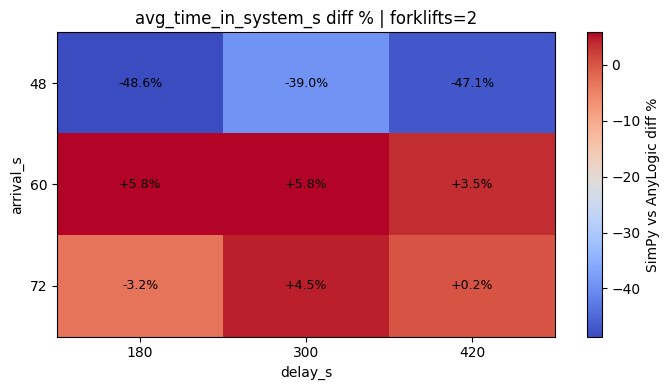

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(matrix.values, aspect="auto", cmap="coolwarm")
ax.set_xticks(range(len(matrix.columns)), labels=[f"{value:g}" for value in matrix.columns])
ax.set_yticks(range(len(matrix.index)), labels=[f"{value:g}" for value in matrix.index])
ax.set_xlabel("delay_s")
ax.set_ylabel("arrival_s")
ax.set_title(f"{metric_name} diff % | forklifts={forklift_count}")
for y in range(matrix.shape[0]):
    for x in range(matrix.shape[1]):
        value = matrix.iloc[y, x]
        ax.text(x, y, f"{value:+.1f}%", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="SimPy vs AnyLogic diff %")
plt.tight_layout()

## Forklift Phase Averages

In [11]:
phase_avg = comparison[comparison["metric"].str.startswith("benchmark_") & comparison["metric"].str.endswith("__average")]
phase_avg.sort_values(["abs_diff_pct", "abs_diff"], ascending=False)[[
    "label", "arrival_s", "forklifts", "delay_s", "anylogic", "simpy", "diff", "diff_pct", "status"
]].head(60)

,label,arrival_s,forklifts,delay_s,anylogic,simpy,diff,diff_pct,status
1014,Retrieve: seize -> loading start [avg],60.0,4,180.0,5.819808,24.513015,18.693207,321.199720,DIFF
873,Retrieve: seize -> loading start [avg],60.0,3,180.0,6.188935,12.521142,6.332206,102.314952,DIFF
262,Retrieve: seize -> loading start [avg],48.0,2,420.0,3.598207,0.000000,-3.598207,-100.000000,DIFF
1249,Retrieve: seize -> loading start [avg],72.0,1,420.0,0.086764,0.000000,-0.086764,-100.000000,DIFF
1202,Retrieve: seize -> loading start [avg],72.0,1,300.0,0.086113,0.000000,-0.086113,-100.000000,DIFF
168,Retrieve: seize -> loading start [avg],48.0,2,180.0,3.295580,5.859789,2.564210,77.807546,DIFF
1108,Retrieve: seize -> loading start [avg],60.0,4,420.0,14.302821,24.513015,10.210194,71.385874,DIFF
215,Retrieve: seize -> loading start [avg],48.0,2,300.0,2.899134,4.661298,1.762165,60.782455,DIFF
497,Retrieve: seize -> loading start [avg],48.0,4,300.0,15.423943,24.513015,9.089073,58.928336,DIFF
1061,Retrieve: seize -> loading start [avg],60.0,4,300.0,15.931132,24.513015,8.581884,53.868640,DIFF


## Re-run Commands

Use these from the repo root when you want to refresh the underlying exports:

```bash
.venv/bin/python -m case_studies.model_2_simpy.run_parameter_variation
.venv/bin/python -m case_studies.model_2_simpy.compare_parameter_variation_range --view overview
.venv/bin/python -m case_studies.model_2_simpy.compare_parameter_variation_range --view offenders --metric benchmark_avg_only --top 25
```